# IA26_P01_G02 — Pesquisa local: Hill-Climbing sobre a solução do Greedy

**Autor desta parte:** Alexandre Silva (29382) · Grupo 02 · Inteligência Artificial 2026/27

O guia pede: *"Local search — Hill-Climbing on top of the Greedy solution. Deliverable: cost vs. iteration curves."*

**O que este notebook faz:**
1. Representa cada rota (um veículo num dia) como uma **sequência de visitas**.
2. Define os **vizinhos** com três movimentos: **trocar**, **mover** e **inverter** visitas.
3. Aplica o **Hill-Climbing**, que só aceita vizinhos **aprovados pelo verificador** do `model.py` (`verificar_viabilidade`).
4. Mostra as **curvas de custo × iteração** no *tiny* e no *small*, a partir do Greedy e de várias soluções iniciais.
5. Como extra, compara com o **Simulated Annealing**.

**Ficheiros:**
| Ficheiro | Conteúdo |
|---|---|
| `local.py` | Representação, vizinhos, avaliação pelo verificador, Hill-Climbing, Simulated Annealing, plano com os dias encadeados |
| `03_pesquisa_local.ipynb` | Este notebook |
| `DOCUMENTACAO.md` | Explicação completa, para estudar e defender |

**De onde vem a solução inicial:** o `local.py` recebe rotas no formato de ações do `verificar_viabilidade` (`pickup`, `warehouse`, `load`, `delivery`), venham de onde vierem. Neste notebook, as rotas iniciais vêm do Greedy da pasta `../pesquisa_informada/`. Quando o `pesquisa.py` final do grupo estiver pronto, basta trocar a função `solucao_greedy()` (secção 1).

In [1]:
import sys, time
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, ".")                       # local.py
sys.path.insert(0, "../pesquisa_informada")   # Greedy (solução inicial)
sys.path.insert(0, "..")                      # model.py

from model import Problem
from local import (PlanoLocal, Contexto, Visita, acoes_para_visitas, visitas_para_acoes, texto_rota,
                   avaliar, vizinhos, aplicar, hill_climbing, curva_total, MOVIMENTOS, MOVIMENTOS_COM_BLOCO)
from pesquisa import planear, melhor_atribuicao
from heuristicas import h_pedido_mais_caro, h_mst, h_mais_distante

tiny = Problem("../docs/data_tiny/")
small = Problem("../docs/data_small_30_31oct2026/")

## 1. Solução inicial: o Greedy

O Greedy devolve, para cada veículo e dia, uma lista de ações. Esta é a única ligação entre a pesquisa informada e a pesquisa local. A divisão das encomendas pelos veículos é a mesma da pesquisa informada.

In [2]:
def solucao_greedy(pb, atribuicao, heuristica):
    # Devolve as rotas do Greedy no formato que o local.py recebe.
    # Para usar o pesquisa.py final do grupo, basta mudar esta função.
    plano = planear(pb, atribuicao, "greedy", heuristica)
    return [dict(vehicle_id=r["vehicle_id"], dia=r["dia"], hora_partida=r["subproblema"].hora_inicio,
                 recolher=r["subproblema"].recolher, entregar=r["subproblema"].entregar, acoes=r["acoes"])
            for r in plano["rotas"]]

def otimo_astar(pb, atribuicao):
    return planear(pb, atribuicao, "astar", h_pedido_mais_caro)["distancia_km"]

atr_tiny, _, _ = melhor_atribuicao(tiny, h_pedido_mais_caro, n_aleatorias=4)
atr_small, fora_small, _ = melhor_atribuicao(small, h_pedido_mais_caro, n_aleatorias=0)
OTIMO = {"tiny": otimo_astar(tiny, atr_tiny), "small": otimo_astar(small, atr_small)}
print("Ótimo do A* (referência):", OTIMO, "| small sem a encomenda", fora_small)

Ótimo do A* (referência): {'tiny': 601.97, 'small': 879.45} | small sem a encomenda [9]


## 2. Representação: sequência de visitas

Cada rota é uma lista de visitas:

| Símbolo | Visita | O que acontece |
|---|---|---|
| `R3` | recolha no produtor 3 | recolhe os itens indicados (10 min) |
| `A(5)` | armazém | descarrega tudo o que vem a bordo (15 min) e carrega 5 itens (15 min) |
| `A` | armazém | só descarrega, ou é o regresso final |
| `E9` | entrega no cliente 9 | entrega os itens indicados (10 min) |

A conversão entre ações e visitas é feita nos dois sentidos (`acoes_para_visitas` e `visitas_para_acoes`). Assim, o verificador avalia sempre a rota exata que estamos a testar. A última visita, o regresso ao armazém, fica sempre no fim.

In [3]:
entradas_tiny = solucao_greedy(tiny, atr_tiny, h_pedido_mais_caro)
e = entradas_tiny[0]
visitas = acoes_para_visitas(tiny, e["acoes"])
print(f"Veículo {e['vehicle_id']}, dia {e['dia']:%d/%m}")
print("Ações (primeiras 8):", e["acoes"][:8], "...")
print("Visitas:", texto_rota(visitas))
print("Conversão de volta igual às ações originais?", visitas_para_acoes(tiny, visitas) == e["acoes"])

Veículo 1, dia 30/10
Ações (primeiras 8): [('pickup', 6), ('pickup', 22), ('pickup', 26), ('pickup', 11), ('pickup', 24), ('pickup', 29), ('pickup', 35), ('warehouse', 4)] ...
Visitas: R3 A R1 R2 A(14) E7 E5 E8 E6 A
Conversão de volta igual às ações originais? True


## 3. Vizinhança: trocar, mover, inverter

Para uma rota com $n$ visitas móveis:

| Movimento | O que faz | Exemplo em `A B C D E` | Nº de vizinhos |
|---|---|---|---|
| **trocar(i, j)** | troca duas visitas | trocar(1, 3) → `A D C B E` | $n(n-1)/2$ |
| **mover(i, j)** | tira uma visita e põe-na noutra posição | mover(1, 3) → `A C D B E` | $\approx n(n-2)$ |
| **inverter(i, j)** | inverte um troço (2-opt) | inverter(1, 4) → `A E D C B` | $(n-1)(n-2)/2$ |

Os repetidos óbvios não são gerados. Por exemplo, mover uma visita para a posição seguinte é o mesmo que trocar duas visitas vizinhas.

In [4]:
ctx = Contexto(tiny, e["vehicle_id"], e["dia"], e["hora_partida"], set(e["recolher"]), set(e["entregar"]))
contagem = {"trocar": 0, "mover": 0, "inverter": 0}
viaveis = {"trocar": 0, "mover": 0, "inverter": 0}
for m, i, j, nova in vizinhos(visitas):
    contagem[m] += 1
    viaveis[m] += avaliar(ctx, nova)[0]
pd.DataFrame({"vizinhos gerados": contagem, "aprovados pelo verificador": viaveis}).assign(
    **{"% aprovados": lambda d: (100 * d["aprovados pelo verificador"] / d["vizinhos gerados"]).round(1)})

,vizinhos gerados,aprovados pelo verificador,% aprovados
trocar,36,1,2.8
mover,64,1,1.6
inverter,28,0,0.0


### 3.1 O verificador como filtro

A maior parte dos vizinhos é **rejeitada pelo verificador**. Por exemplo, trocar a ordem de duas visitas pode fazer:
- chegar a um produtor depois de a janela fechar;
- carregar no armazém um item que ainda não foi recolhido;
- entregar fora da janela.

O Hill-Climbing nunca passa por soluções inválidas. Um exemplo de vizinho rejeitado:

In [5]:
for m, i, j, nova in vizinhos(visitas):
    ok, km, res = avaliar(ctx, nova)
    if not ok and res["erros"]:
        print(f"{m}({i}, {j}):  {texto_rota(nova)}")
        for erro in res["erros"][:3]:
            print("   -", erro)
        break

trocar(0, 1):  A R3 R1 R2 A(14) E7 E5 E8 E6 A
   - Item 36: excesso de capacidade no veículo 1 (159.2 kg > 150.0 kg).
   - Item 38: excesso de capacidade no veículo 1 (163.2 kg > 150.0 kg).
   - Item 39: excesso de capacidade no veículo 1 (166.9 kg > 150.0 kg).


## 4. Hill-Climbing

```
atual = solução do Greedy
repetir:
    para cada vizinho de atual (trocar, mover, inverter):
        se o verificador o aprova e tem menos km  → candidato
    se não há candidatos: parar (ótimo local)
    atual = melhor candidato          (estratégia "melhor", steepest ascent)
         ou primeiro candidato        (estratégia "primeiro", first improvement, ordem aleatória)
```

- **Função de custo:** km totais da rota, calculados pelo verificador.
- **Dias encadeados:** uma rota do dia 30 decide a que horas os itens que passam a noite chegam ao armazém. O limite de 24 h depende disso. Por isso, ao otimizar o dia 30, só se aceitam vizinhos que mantêm viáveis as rotas do dia 31 (`PlanoLocal._dia_seguinte_ok`). As rotas são otimizadas por ordem cronológica.

## 5. *Tiny*: Hill-Climbing a partir do Greedy

In [6]:
def correr(pb, entradas, metodo="hc", **par):
    plano = PlanoLocal.de_acoes(pb, entradas)
    c0 = plano.custo_total()
    rotas_iniciais = {k: texto_rota(r.visitas) for k, r in plano.rotas.items()}
    t0 = time.perf_counter()
    res = plano.otimizar(metodo, **par)
    res["tempo_total_s"] = round(time.perf_counter() - t0, 3)
    res["custo_inicial_km"] = c0
    res["curva"] = curva_total(res, c0)
    res["rotas_iniciais"] = rotas_iniciais
    res["plano"] = plano
    return res

def tabela_rotas(res):
    linhas = []
    for (v, d), r in sorted(res["rotas"].items()):
        h = r["historico"]
        linhas.append({"veículo": v, "dia": d.day, "km Greedy": r["custo_inicial_km"], "km final": r["custo_km"],
                       "melhoria (km)": round(r["custo_inicial_km"] - r["custo_km"], 2),
                       "iterações": r["iteracoes"], "chamadas ao verificador": r["avaliacoes_verificador"],
                       "movimentos aplicados": ", ".join(x["movimento"] for x in h[1:]) or "—",
                       "rota inicial": res["rotas_iniciais"][(v, d)], "rota final": h[-1]["rota"]})
    return pd.DataFrame(linhas)

hc_tiny = correr(tiny, entradas_tiny, "hc", estrategia="melhor")
print(f"Total: {hc_tiny['custo_inicial_km']} km (Greedy) → {hc_tiny['custo_total_km']} km (Hill-Climbing) · "
      f"ótimo do A*: {OTIMO['tiny']} km · plano válido: {hc_tiny['valido']} · {hc_tiny['tempo_total_s']} s")
tabela_rotas(hc_tiny)

Total: 609.59 km (Greedy) → 601.97 km (Hill-Climbing) · ótimo do A*: 601.97 km · plano válido: True · 0.054 s


,veículo,dia,km Greedy,km final,melhoria (km),iterações,chamadas ao verificador,movimentos aplicados,rota inicial,rota final
0,1,30,278.73,273.07,5.66,1,257,"trocar(5, 6)",R3 A R1 R2 A(14) E7 E5 E8 E6 A,R3 A R1 R2 A(14) E5 E7 E8 E6 A
1,1,31,237.07,235.11,1.96,1,325,"trocar(6, 8)",A(5) R3 R2 R1 E9 A(16) E7 E9 E5 E6 A,A(5) R3 R2 R1 E9 A(16) E5 E9 E7 E6 A
2,2,31,93.79,93.79,0.00,0,9,—,A(5) E8 E6 A,A(5) E8 E6 A


No *tiny*, o Greedy com H1 e o Greedy com H2 dão exatamente a mesma rota (609,59 km). **O Hill-Climbing chega ao ótimo do A\*** com uma só iteração em cada uma das 2 rotas que melhoram.

## 6. *Small*: Hill-Climbing a partir de três soluções do Greedy

No *small*, o Greedy dá soluções diferentes consoante a heurística. Assim, o Hill-Climbing parte de três pontos iniciais diferentes.

In [7]:
INICIAIS = {"Greedy H1 (pedido mais caro)": h_pedido_mais_caro,
            "Greedy H2 (MST)": h_mst,
            "Greedy Ref. (mais distante)": h_mais_distante}
hc_small, linhas = {}, []
for nome, h in INICIAIS.items():
    for estrategia in ["melhor", "primeiro"]:
        res = correr(small, solucao_greedy(small, atr_small, h), "hc", estrategia=estrategia, semente=1)
        hc_small[(nome, estrategia)] = res
        linhas.append({"solução inicial": nome, "estratégia HC": estrategia,
                       "km inicial": res["custo_inicial_km"], "km final": res["custo_total_km"],
                       "melhoria (km)": round(res["custo_inicial_km"] - res["custo_total_km"], 2),
                       "acima do ótimo (km)": round(res["custo_total_km"] - OTIMO["small"], 2),
                       "iterações": sum(r["iteracoes"] for r in res["rotas"].values()),
                       "chamadas ao verificador": sum(r["avaliacoes_verificador"] for r in res["rotas"].values()),
                       "tempo (s)": res["tempo_total_s"], "plano válido": res["valido"]})
print(f"Ótimo do A* no small: {OTIMO['small']} km")
pd.DataFrame(linhas)

Ótimo do A* no small: 879.45 km


,solução inicial,estratégia HC,km inicial,km final,melhoria (km),acima do ótimo (km),iterações,chamadas ao verificador,tempo (s),plano válido
0,Greedy H1 (pedido mais caro),melhor,880.53,880.53,0.00,1.08,0,712,0.115,True
1,Greedy H1 (pedido mais caro),primeiro,880.53,880.53,0.00,1.08,0,712,0.110,True
2,Greedy H2 (MST),melhor,940.42,880.53,59.89,1.08,2,968,0.133,True
3,Greedy H2 (MST),primeiro,940.42,880.53,59.89,1.08,2,765,0.125,True
4,Greedy Ref. (mais distante),melhor,913.58,879.45,34.13,0.00,1,840,0.168,True
5,Greedy Ref. (mais distante),primeiro,913.58,879.45,34.13,0.00,2,818,0.111,True


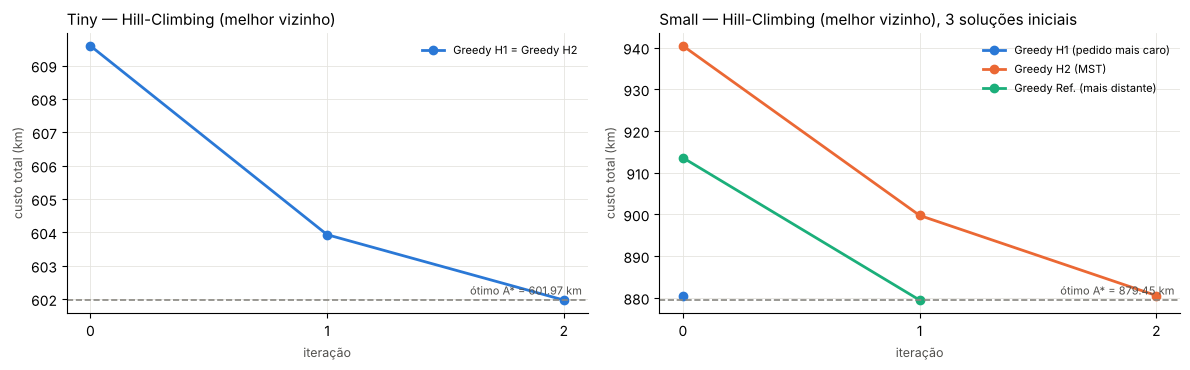

In [8]:
CORES = ["#2a78d6", "#eb6834", "#1baf7a"]   # ordem fixa: azul, laranja, verde-água
CINZA = "#898781"

def estilo(ax, titulo, ylabel="custo total (km)"):
    ax.set_title(titulo, fontsize=11, loc="left")
    ax.set_xlabel("iteração", fontsize=9, color="#52514e")
    ax.set_ylabel(ylabel, fontsize=9, color="#52514e")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e5e4df", linewidth=0.6)
    ax.set_axisbelow(True)

def linha_otimo(ax, valor):
    ax.axhline(valor, color=CINZA, linewidth=1.2, linestyle="--")
    ax.annotate(f"ótimo A* = {valor} km", xy=(1, valor), xycoords=("axes fraction", "data"),
                xytext=(-4, 4), textcoords="offset points", ha="right", fontsize=8, color="#52514e")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
c = hc_tiny["curva"]
axes[0].plot(range(len(c)), c, color=CORES[0], linewidth=2, marker="o", markersize=6, label="Greedy H1 = Greedy H2")
linha_otimo(axes[0], OTIMO["tiny"])
estilo(axes[0], "Tiny — Hill-Climbing (melhor vizinho)")
axes[0].legend(frameon=False, fontsize=8)
for cor, nome in zip(CORES, INICIAIS):
    c = hc_small[(nome, "melhor")]["curva"]
    axes[1].plot(range(len(c)), c, color=cor, linewidth=2, marker="o", markersize=6, label=nome)
linha_otimo(axes[1], OTIMO["small"])
estilo(axes[1], "Small — Hill-Climbing (melhor vizinho), 3 soluções iniciais")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.xaxis.get_major_locator().set_params(integer=True)
plt.tight_layout()
plt.show()

**Leitura:**
- **Do Greedy H2 (MST), o Hill-Climbing tira cerca de 60 km** em 2 iterações. Do Greedy "mais distante", chega ao ótimo.
- **O Greedy H1 (880,53 km) já é um ótimo local.** Nenhum vizinho viável melhora, mas ainda está 1,08 km acima do ótimo.
  - O ótimo do A\* tem **exatamente as mesmas visitas**, só que as entregas `E10` e `E9` aparecem logo a seguir a `R4`.
  - Para lá chegar, é preciso mover duas visitas ao mesmo tempo. Cada passo isolado é inviável ou piora.
  - A secção 9 mostra como um 4.º movimento resolve isto.

## 7. Várias soluções iniciais (10 sementes)

Partindo de soluções do Greedy, que já são boas, o Hill-Climbing faz poucas iterações. Para testar o algoritmo a sério, criamos **10 soluções iniciais piores**, baralhando a do Greedy com 40 movimentos aleatórios viáveis (`PlanoLocal.perturbar`). Depois comparamos três métodos a partir de cada uma:
- **HC melhor:** steepest ascent;
- **HC primeiro:** first improvement, com ordem aleatória;
- **SA:** Simulated Annealing, o extra. Começa com T = 20 km e multiplica a temperatura por 0,995 em cada iteração, durante 3000 iterações por rota.

In [9]:
METODOS = {"HC melhor": ("hc", dict(estrategia="melhor")),
           "HC primeiro": ("hc", dict(estrategia="primeiro")),
           "SA (extra)": ("sa", dict())}

def experiencia(pb, entradas, otimo, sementes=range(10), passos=40):
    base = PlanoLocal.de_acoes(pb, entradas)
    linhas, guardados = [], {}
    for s in sementes:
        inicial = base.copia()
        inicial.perturbar(passos=passos, semente=s)
        c0 = inicial.custo_total()
        for nome, (met, par) in METODOS.items():
            p = inicial.copia()
            par = dict(par, semente=s) if nome != "HC melhor" else par
            t0 = time.perf_counter()
            res = p.otimizar(met, **par)
            res["curva"] = curva_total(res, c0)
            guardados[(s, nome)] = res
            linhas.append({"semente": s, "método": nome, "km inicial": c0, "km final": res["custo_total_km"],
                           "chegou ao ótimo": abs(res["custo_total_km"] - otimo) < 0.01,
                           "iterações": sum(r["iteracoes"] for r in res["rotas"].values()) if met == "hc" else None,
                           "chamadas ao verificador": sum(r["avaliacoes_verificador"] for r in res["rotas"].values()),
                           "tempo (s)": round(time.perf_counter() - t0, 3), "válido": res["valido"]})
    return pd.DataFrame(linhas), guardados

def resumo(df):
    return df.groupby("método", sort=False).agg(
        km_inicial_medio=("km inicial", "mean"), km_final_medio=("km final", "mean"),
        km_final_min=("km final", "min"), km_final_max=("km final", "max"),
        vezes_no_otimo=("chegou ao ótimo", "sum"), iteracoes_medias=("iterações", "mean"),
        chamadas_verificador_medias=("chamadas ao verificador", "mean"),
        tempo_medio_s=("tempo (s)", "mean"), todos_validos=("válido", "all")).round(2)

exp_tiny, guard_tiny = experiencia(tiny, entradas_tiny, OTIMO["tiny"])
print(f"Tiny — ótimo {OTIMO['tiny']} km")
resumo(exp_tiny)

Tiny — ótimo 601.97 km


,km_inicial_medio,km_final_medio,km_final_min,km_final_max,vezes_no_otimo,iteracoes_medias,chamadas_verificador_medias,tempo_medio_s,todos_validos
método,,,,,,,,,
HC melhor,623.35,601.97,601.97,601.97,10,1.3,508.2,0.06,True
HC primeiro,623.35,601.97,601.97,601.97,10,1.7,374.7,0.04,True
SA (extra),623.35,601.97,601.97,601.97,10,NaN,9003.0,0.74,True


In [10]:
entradas_small = solucao_greedy(small, atr_small, h_pedido_mais_caro)
exp_small, guard_small = experiencia(small, entradas_small, OTIMO["small"])
print(f"Small — ótimo {OTIMO['small']} km")
resumo(exp_small)

Small — ótimo 879.45 km


,km_inicial_medio,km_final_medio,km_final_min,km_final_max,vezes_no_otimo,iteracoes_medias,chamadas_verificador_medias,tempo_medio_s,todos_validos
método,,,,,,,,,
HC melhor,934.98,880.42,879.45,880.53,1,3.1,1688.4,0.33,True
HC primeiro,934.98,880.42,879.45,880.53,1,4.0,1181.3,0.21,True
SA (extra),934.98,880.42,879.45,880.53,1,NaN,12004.0,1.42,True


In [11]:
exp_small.pivot(index="semente", columns="método", values="km final").assign(
    **{"km inicial": exp_small.groupby("semente")["km inicial"].first()})

método,HC melhor,HC primeiro,SA (extra),km inicial
semente,,,,
0,880.53,880.53,880.53,938.95
1,880.53,880.53,880.53,913.75
2,880.53,880.53,880.53,946.54
3,879.45,880.53,880.53,960.36
4,880.53,880.53,880.53,920.51
5,880.53,879.45,879.45,936.72
6,880.53,880.53,880.53,944.37
7,880.53,880.53,880.53,920.97
8,880.53,880.53,880.53,947.88


### 7.1 Curvas de custo × iteração

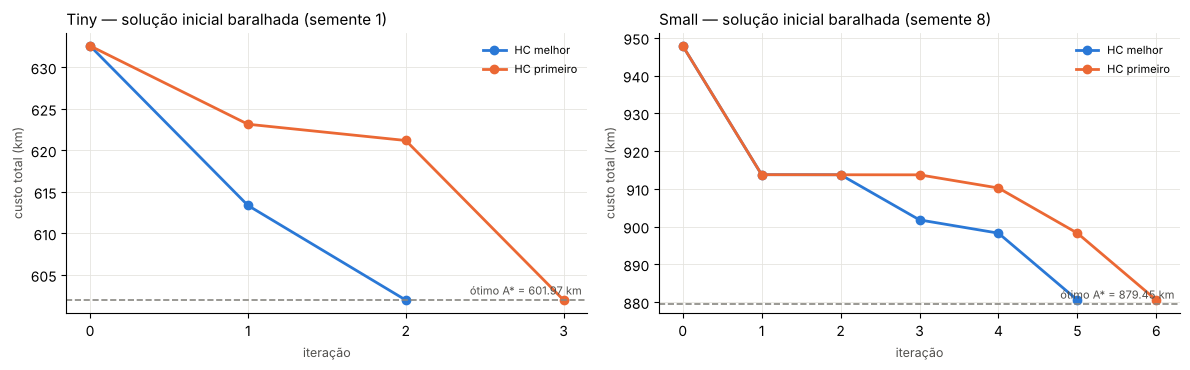

In [12]:
def semente_mais_longa(df):
    hc = df[df["método"] == "HC melhor"]
    return int(hc.sort_values("iterações", ascending=False)["semente"].iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nome_ds, df, guard) in zip(axes, [("Tiny", exp_tiny, guard_tiny), ("Small", exp_small, guard_small)]):
    s = semente_mais_longa(df)
    for cor, metodo in zip(CORES, ["HC melhor", "HC primeiro"]):
        c = guard[(s, metodo)]["curva"]
        ax.plot(range(len(c)), c, color=cor, linewidth=2, marker="o", markersize=6, label=metodo)
    linha_otimo(ax, OTIMO[nome_ds.lower()])
    estilo(ax, f"{nome_ds} — solução inicial baralhada (semente {s})")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

O **HC melhor** dá passos maiores, porque escolhe sempre o melhor vizinho, e por isso precisa de menos iterações. Cada iteração custa mais, porque avalia todos os vizinhos. O **HC primeiro** dá passos mais pequenos e faz mais iterações, mas cada uma é mais barata: aceita o primeiro vizinho que melhora.

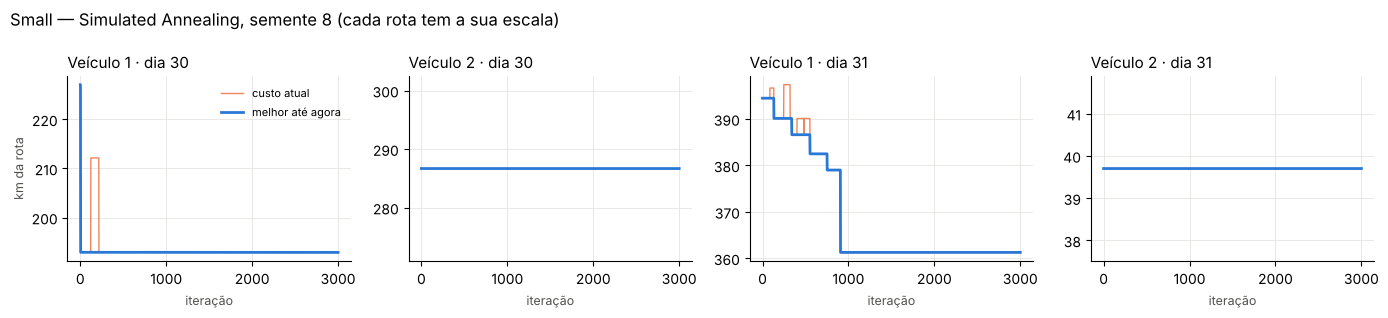

In [13]:
s = semente_mais_longa(exp_small)
res_sa = guard_small[(s, "SA (extra)")]
rotas_sa = sorted(res_sa["rotas"].items(), key=lambda kv: (kv[0][1], kv[0][0]))
fig, axes = plt.subplots(1, len(rotas_sa), figsize=(14, 3.2))
for ax, ((v, d), r) in zip(axes, rotas_sa):
    h = r["historico"]
    ax.plot([x["custo_km"] for x in h], color=CORES[1], linewidth=1, alpha=0.8, label="custo atual")
    ax.plot([x["melhor_km"] for x in h], color=CORES[0], linewidth=2, label="melhor até agora")
    estilo(ax, f"Veículo {v} · dia {d.day}", ylabel="km da rota" if ax is axes[0] else "")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Small — Simulated Annealing, semente {s} (cada rota tem a sua escala)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

O Simulated Annealing aceita algumas pioras no início, quando a temperatura está alta (a linha laranja sobe acima da azul). Depois estabiliza. Com estes parâmetros, chega ao mesmo resultado que o Hill-Climbing, mas faz cerca de 7 a 24 vezes mais chamadas ao verificador.

## 8. Que movimentos ajudam mais?

In [14]:
from collections import Counter
usos = Counter()
for guard in (guard_tiny, guard_small):
    for (s, metodo), res in guard.items():
        if metodo.startswith("HC"):
            for r in res["rotas"].values():
                for passo in r["historico"][1:]:
                    usos[passo["movimento"].split("(")[0]] += 1
total = sum(usos.values())
pd.DataFrame({"vezes aplicado": usos}).assign(**{"%": lambda d: (100 * d["vezes aplicado"] / total).round(1)})

,vezes aplicado,%
trocar,48,47.5
mover,49,48.5
inverter,4,4.0


## 9. Extra: um 4.º movimento, mover bloco (or-opt)

Para sair do ótimo local de 880,53 km, acrescentámos um movimento opcional: **mover bloco**. Tira 2 ou 3 visitas seguidas e põe-nas noutra posição, na mesma ordem ou invertidas. Exemplo: `mover_bloco2_inv(4, 2)` em `A R4 R6 R1 E9 E10 …` dá `A R4 E10 E9 R6 R1 …`. É exatamente a mudança que faltava.

In [15]:
linhas = []
for nome, h in INICIAIS.items():
    ent = solucao_greedy(small, atr_small, h)
    for etiqueta, mov in [("3 movimentos", MOVIMENTOS), ("3 + mover bloco", MOVIMENTOS_COM_BLOCO)]:
        res = correr(small, ent, "hc", estrategia="melhor", movimentos=mov)
        linhas.append({"solução inicial": nome, "vizinhança": etiqueta, "km inicial": res["custo_inicial_km"],
                       "km final": res["custo_total_km"],
                       "acima do ótimo (km)": round(res["custo_total_km"] - OTIMO["small"], 2),
                       "chamadas ao verificador": sum(r["avaliacoes_verificador"] for r in res["rotas"].values()),
                       "tempo (s)": res["tempo_total_s"], "plano válido": res["valido"]})
pd.DataFrame(linhas)

,solução inicial,vizinhança,km inicial,km final,acima do ótimo (km),chamadas ao verificador,tempo (s),plano válido
0,Greedy H1 (pedido mais caro),3 movimentos,880.53,880.53,1.08,712,0.137,True
1,Greedy H1 (pedido mais caro),3 + mover bloco,880.53,879.45,0.00,3122,0.554,True
2,Greedy H2 (MST),3 movimentos,940.42,880.53,1.08,968,0.133,True
3,Greedy H2 (MST),3 + mover bloco,940.42,879.45,0.00,3770,0.633,True
4,Greedy Ref. (mais distante),3 movimentos,913.58,879.45,0.00,840,0.115,True
5,Greedy Ref. (mais distante),3 + mover bloco,913.58,879.45,0.00,2212,0.305,True


In [16]:
base = PlanoLocal.de_acoes(small, entradas_small)
linhas, curvas_bloco = [], {}
for sem in range(10):
    inicial = base.copia()
    inicial.perturbar(passos=40, semente=sem)
    c0 = inicial.custo_total()
    for etiqueta, mov in [("3 movimentos", MOVIMENTOS), ("3 + mover bloco", MOVIMENTOS_COM_BLOCO)]:
        p = inicial.copia()
        res = p.otimizar("hc", estrategia="melhor", movimentos=mov)
        curvas_bloco[(sem, etiqueta)] = curva_total(res, c0)
        linhas.append({"semente": sem, "vizinhança": etiqueta, "km inicial": c0, "km final": res["custo_total_km"],
                       "chegou ao ótimo": abs(res["custo_total_km"] - OTIMO["small"]) < 0.01,
                       "chamadas ao verificador": sum(r["avaliacoes_verificador"] for r in res["rotas"].values()),
                       "válido": res["valido"]})
bloco = pd.DataFrame(linhas)
bloco.groupby("vizinhança", sort=False).agg(vezes_no_otimo=("chegou ao ótimo", "sum"),
                                            km_final_medio=("km final", "mean"),
                                            chamadas_verificador_medias=("chamadas ao verificador", "mean"),
                                            todos_validos=("válido", "all")).round(2)

,vezes_no_otimo,km_final_medio,chamadas_verificador_medias,todos_validos
vizinhança,,,,
3 movimentos,1,880.42,1688.4,True
3 + mover bloco,10,879.45,5641.0,True


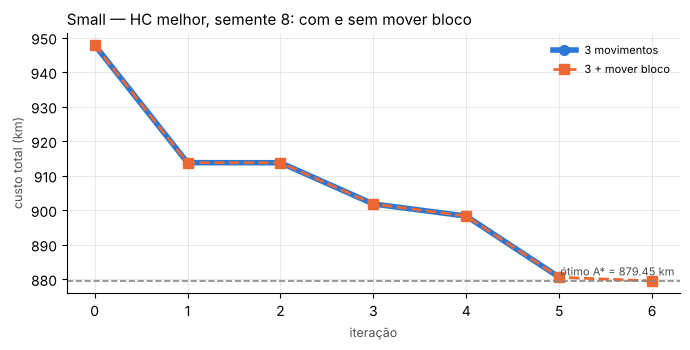

In [17]:
sem = semente_mais_longa(exp_small)
fig, ax = plt.subplots(figsize=(7, 3.6))
for cor, etiqueta, estilo_linha, marcador, larg in [(CORES[0], "3 movimentos", "-", "o", 4),
                                                   (CORES[1], "3 + mover bloco", "--", "s", 2)]:
    c = curvas_bloco[(sem, etiqueta)]
    ax.plot(range(len(c)), c, color=cor, linewidth=larg, linestyle=estilo_linha, marker=marcador,
            markersize=7, label=etiqueta)
linha_otimo(ax, OTIMO["small"])
estilo(ax, f"Small — HC melhor, semente {sem}: com e sem mover bloco")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 10. Análise crítica

### 10.1 O que o Hill-Climbing consegue
- **No *tiny*, chega sempre ao ótimo do A\*** (601,97 km):
  - a partir do Greedy (609,59 km), com 1 iteração em cada uma das 2 rotas que melhoram;
  - a partir das 10 soluções baralhadas (623 km em média), com qualquer método.
- **No *small*, melhora muito as soluções fracas:**
  - Greedy H2 (MST): 940,42 → 880,53 km, menos 59,89 km;
  - Greedy "mais distante": 913,58 → 879,45 km, que é o ótimo;
  - 10 soluções baralhadas: 935 km em média → 880,4 km.
- **Todas as rotas finais foram aprovadas pelo verificador**, com os dois dias encadeados (limite de 24 h).

### 10.2 Ótimos locais
- **Com os três movimentos do plano, o *small* fica quase sempre preso em 880,53 km**, a 1,08 km do ótimo. Só 1 em 10 sementes chega ao ótimo, com qualquer método.
- **O motivo:** a melhor rota tem as mesmas visitas que o ótimo local, mas com duas entregas (`E10`, `E9`) noutra posição. Para lá chegar, é preciso mudar as duas ao mesmo tempo, e cada passo isolado é inviável (janelas) ou piora. É o problema clássico dos ótimos locais do Hill-Climbing.
- **O movimento extra *mover bloco* resolve isto:** o HC passa a chegar ao ótimo em **10 de 10** sementes. Em troca, faz cerca de 3 vezes mais chamadas ao verificador (5641 contra 1688, em média). A escolha da vizinhança pesa mais do que a estratégia de aceitação.

### 10.3 HC "melhor" contra HC "primeiro"
- **Chegam aos mesmos resultados finais.**
- **O "primeiro" faz menos chamadas ao verificador** (25–30 % menos) e é um pouco mais rápido, mas precisa de mais iterações, porque dá passos mais pequenos.
- **O "melhor" dá os passos maiores**, e a curva desce mais depressa por iteração.

### 10.4 Simulated Annealing (extra)
- **Com T₀ = 20 km e arrefecimento de 0,995, não fez melhor do que o Hill-Climbing.** Ficou no mesmo ótimo local 9 vezes em 10 e fez cerca de 7 a 24 vezes mais chamadas ao verificador.
- **A razão:** menos de 3 % dos vizinhos são viáveis. A maior parte das pioras que o SA podia aceitar é inviável, por isso tem pouca margem para "saltar" para outra zona.

### 10.5 O verificador como filtro
- **Só 0 a 3 % dos vizinhos gerados são viáveis.** As janelas temporais, a capacidade e a ordem produtor → armazém → cliente tornam a vizinhança muito restrita.
- **Usar o verificador do `model.py` como filtro garante que nunca se aceita uma rota inválida**, à custa de muitas avaliações. Mesmo assim, cada execução no *small* leva menos de 0,5 s.

### 10.6 Movimentos mais úteis
- **Trocar e mover são cerca de 95 % das melhorias.**
- **Inverter quase nunca é aceite**, porque inverter um troço inteiro de uma rota com janelas temporais costuma torná-la inviável.

### 10.7 Limitações e melhorias futuras
1. **Os vizinhos só mudam a ordem das visitas.** Não mudam que itens se recolhem em cada visita, nem trocam encomendas entre veículos. Novos movimentos possíveis: partir ou juntar visitas, e passar uma encomenda de um veículo para o outro (ligação ao CSP).
2. **As rotas são otimizadas uma a uma**, por ordem cronológica. Uma otimização conjunta dos dois dias podia encontrar compromissos melhores.
3. **O Simulated Annealing podia ser afinado:** temperatura inicial, arrefecimento e número de iterações.
4. **Reinícios aleatórios (random restart)** são uma alternativa simples para escapar a ótimos locais, como mostram as 10 sementes.

## 11. Conclusão
- **O Hill-Climbing sobre a solução do Greedy funciona como o guia pede:**
  - só aceita vizinhos aprovados pelo verificador;
  - melhora sempre ou mantém a solução;
  - as curvas de custo × iteração mostram a descida até a um ótimo local.
- **No *tiny*, chega ao ótimo.** No *small*, recupera quase toda a diferença das soluções fracas do Greedy.
- **A principal lição é a dos ótimos locais:** com trocar, mover e inverter, o *small* fica preso a 1,08 km do ótimo. Juntando o movimento mover bloco, chega ao ótimo em todas as sementes.
- **Ferramentas:** Python, o `model.py` do grupo (verificador), pandas e matplotlib.